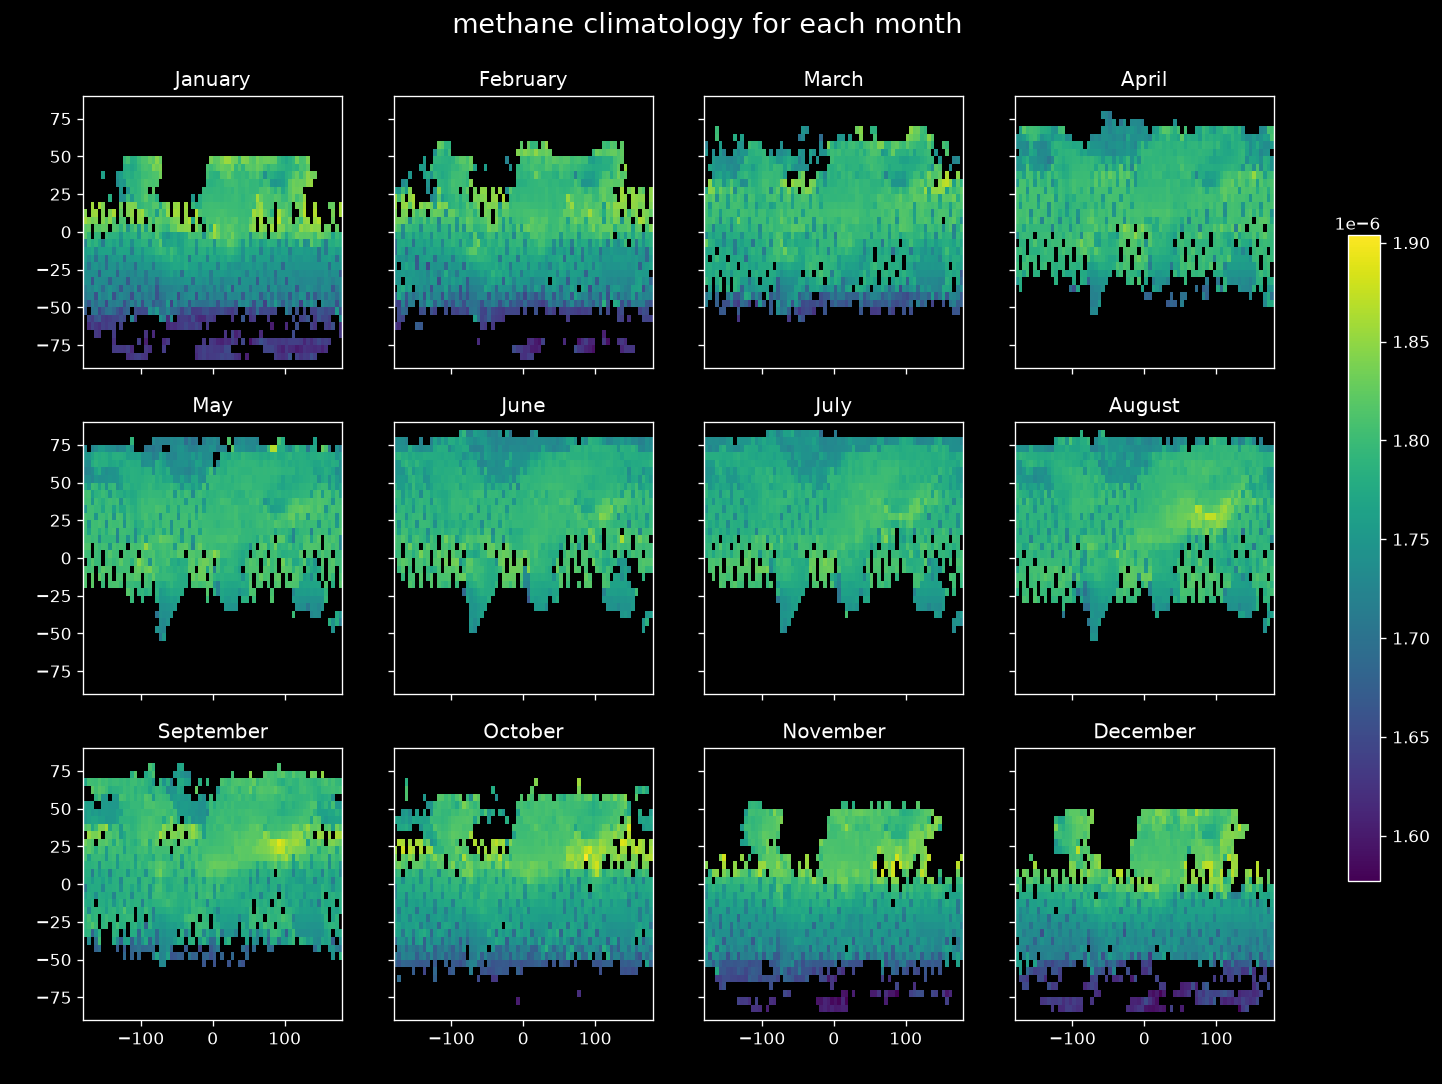

In [24]:
# 1.1
# 导入模块
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# 读取文件
CH4_data =  xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc", engine="netcdf4")
# 获取数据参数得知xch4是甲烷浓度数据
CH4_data.data_vars
CH4_data['xch4']
# 剔除缺测值
CH4 = CH4_data["xch4"].where(CH4_data["xch4"]< 1e-3)
# 按12月进行分组并获得每月气候均值
xch4_clim = CH4.groupby('time.month').mean()

# 创建3行4列的子图网格，一共12个网格，设置画布大小以及分辨率。坐标轴共享，每一行第一个图显示Y轴，每一列最后一个图显示X轴
fig, axes = plt.subplots(3,4, figsize=(16,10),  sharex="col", sharey="row", dpi=120)  
# 设置子图标签
fields  = {0:'January', 1:'February', 2:'March', 3:'April', 4: 'May', 5: 'June', 6: 'July', 7: 'August', 8: 'September', 9: 'October', 10: 'November', 11: 'December'}

# 采用for循环遍历每个子图，子图不显示色带（12个色带太复杂），统一色标范围vmin/vmax，子图要在外围显示坐标轴刻度标签
for i, ax in enumerate(axes.ravel()):
    month_num = i + 1
    im = xch4_clim.sel(month=month_num).plot(ax=ax, add_colorbar=False, vmin=xch4_clim.min(), vmax=xch4_clim.max())
    ax.set_title(fields[i])
    ax.label_outer()

# 总标题，确定位置在最上方居中
plt.suptitle('methane climatology for each month', x=0.45, y=0.95,fontsize=16)   #suptitle= 整个画布的总标题（大标题），区别于每个子图自己的set_title()
# 为12个子图画一个色带
fig.colorbar(im, ax=axes, shrink=0.7)

plt.show()

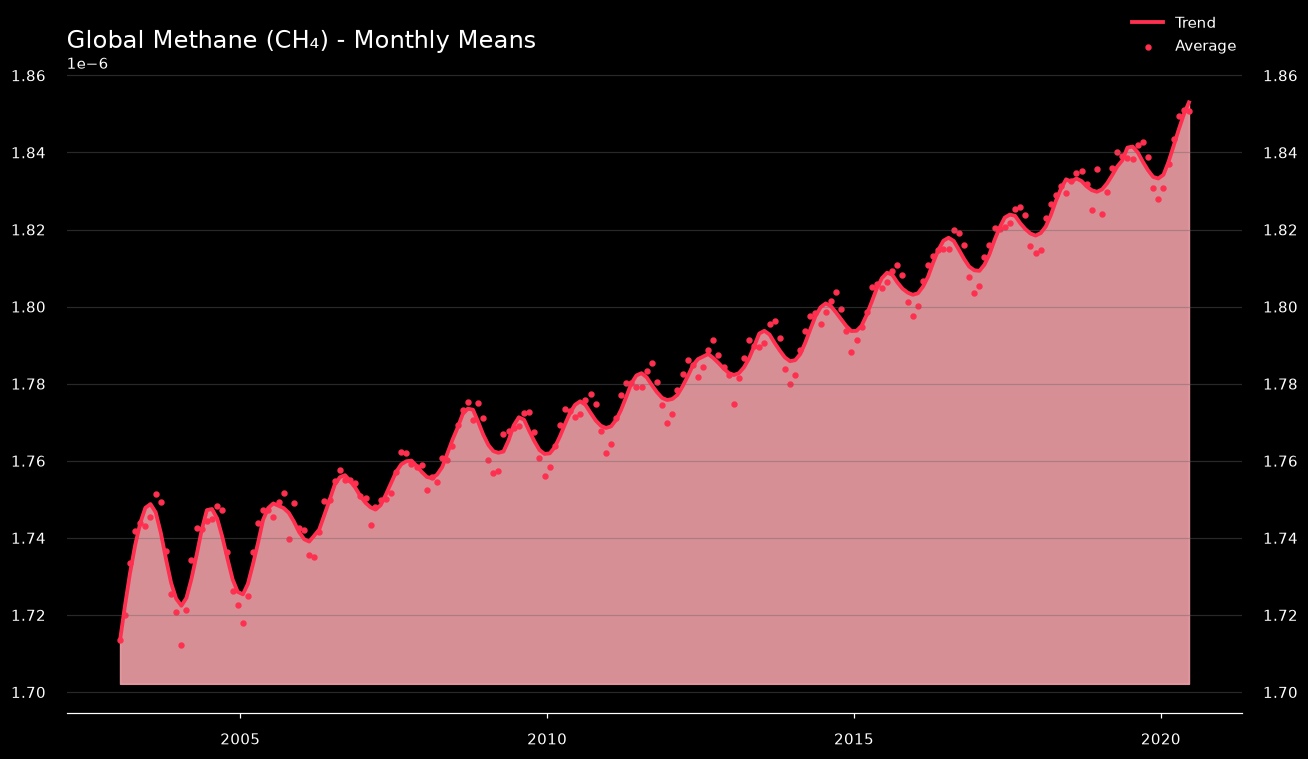

In [25]:
#1.2
#不导入模块等偶尔会报错，所以每一题都重新导入模块读取数据
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib as mpl
import matplotlib.dates as mdates
from scipy.signal import savgol_filter

CH4_data =  xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc", engine="netcdf4")
CH4_data['xch4']

# 获取2003-01 到 2020-06甲烷浓度数据
CH4 = CH4_data.xch4.sel(time=slice("2003-01", "2020-06"))

# 剔除缺测值
CH4 = CH4.where(CH4 < 1e-3)

# 根据纬度的余弦值计算权重；然后使用 xarray 函数将这些权重应用于数据数组： weighted()
lat_weights = np.cos(np.deg2rad(CH4.lat))
lat_weights.name = "weights"
CH4_weighted = CH4.weighted(lat_weights)
# 在lat、lon维度求加权平均
CH4_global_mean = CH4_weighted.mean(['lat', 'lon'])


# 转为时间序列
series = CH4_global_mean.to_series().interpolate()
time, CH4_val = series.index, series.values      #线性插值补齐 NaN 空缺月份，使曲线不断开
y_trend = savgol_filter(CH4_val, 11, 3)          #算出平滑长期趋势线
baseline = CH4_val.min()- 1e-8
 
# 新建画布，设置子图背景黑色，文字、刻度白色，网格灰色
plt.rcParams.update({
    "figure.facecolor": "black",
    "axes.facecolor": "black",
    "text.color": "white",
    "xtick.color": "white",
    "axes.edgecolor": "white",
    "ytick.color": "white",
    "grid.color": "#666666",
})

# 绘制趋势线与基线间的浅粉色填充区域，画出红色平滑趋势线、红色月均值散点，标题靠左对齐
fig, ax = plt.subplots(figsize=(12, 7), dpi=110)
ax.fill_between(time, y_trend, baseline, color="#f0a0a8", alpha=0.9)
ax.plot(time, y_trend, c="#ff304f", lw=2.5, label="Trend")
ax.scatter(time, CH4_val, c="#ff304f", s=10, label="Average")
ax.set_title("Global Methane (CH₄) - Monthly Means", fontsize=16, loc="left")

# X轴刻度以5年为距，显示年份
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# 去掉矩形边框，只保留底部时间轴
for name, spine in ax.spines.items():
    spine.set_visible(name == "bottom")
# 设置坐标轴刻度样式，添加横向网格，放置图例
ax.tick_params(axis="x", length=3, pad=10)
ax.tick_params(axis="y", left=False, right=False, labelleft=True, labelright=True, pad=10)
ax.grid(axis="y", alpha=0.4)
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.02), ncol=1, frameon=False, borderaxespad=0)
plt.tight_layout()
plt.show()

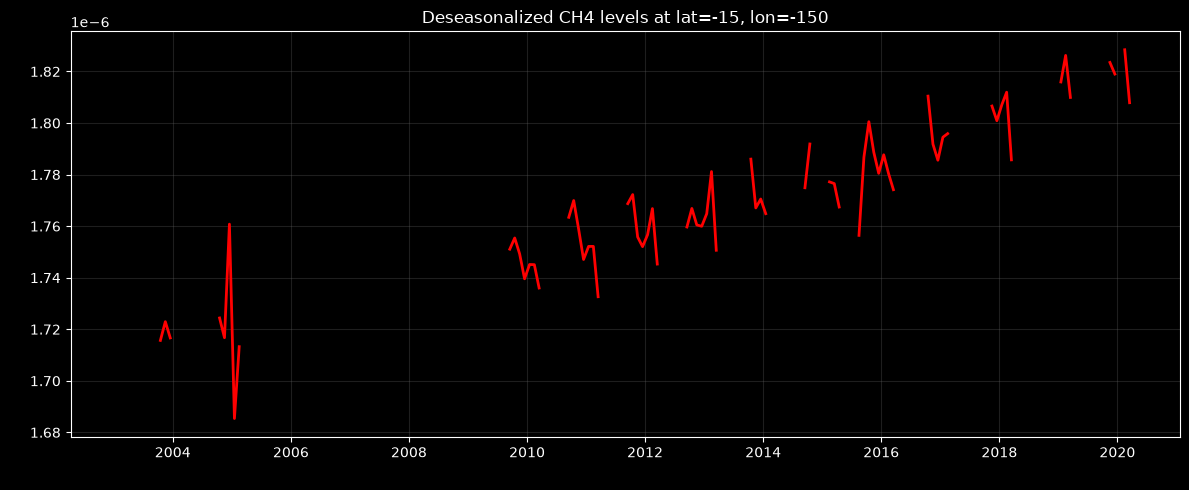

In [6]:
#1.3
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

CH4_data =  xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc", engine="netcdf4")
CH4_data.data_vars
CH4_data['xch4']
CH4 = CH4_data.xch4.sel(time=slice("2003-01", "2020-06"))
CH4 = CH4.where(CH4 < 1e-3)

# 提取单点时间序列
xch4_point = CH4.sel(lat=-15, lon=-150, method='nearest')

# 按月份分组，获取12个月该点多年均值
climatology = xch4_point.groupby("time.month").mean("time")
# 按月份分组后每个原始观测值，减去它对应月份的多年平均气候值
anomalies = xch4_point.groupby("time.month") - climatology
# 加回长期平均值，得到去季节化浓度水平
deseasonalized_level = anomalies + xch4_point.mean("time")

# 绘图
plt.figure(figsize=(12,5))
deseasonalized_level.plot(color="red", linewidth=2)
plt.title("Deseasonalized CH4 levels at lat=-15, lon=-150")
plt.xlabel("T")
plt.ylabel("Deseasonalized CH4 levels")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

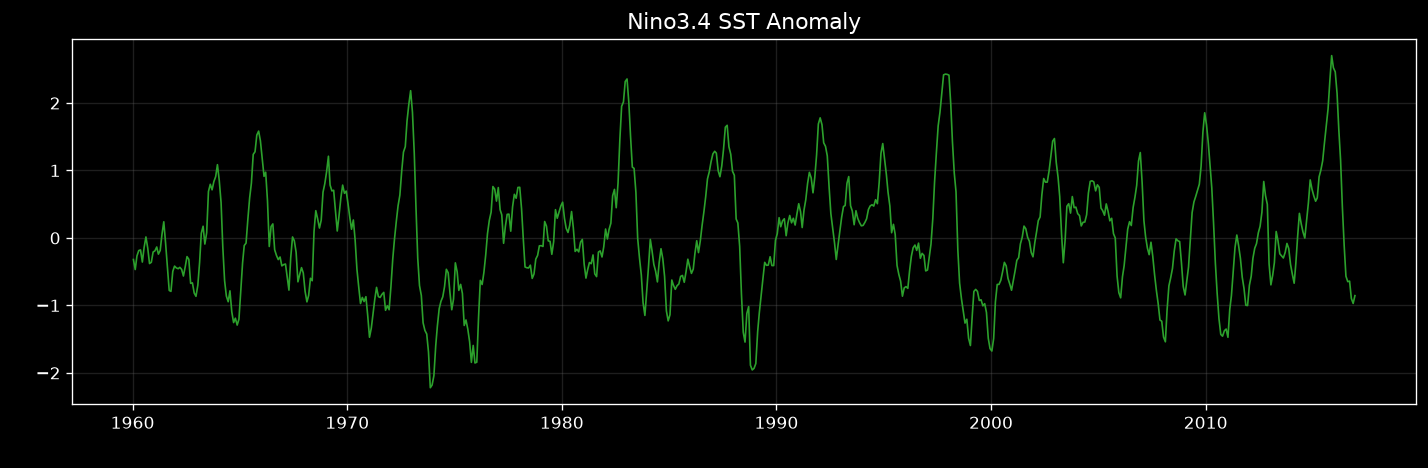

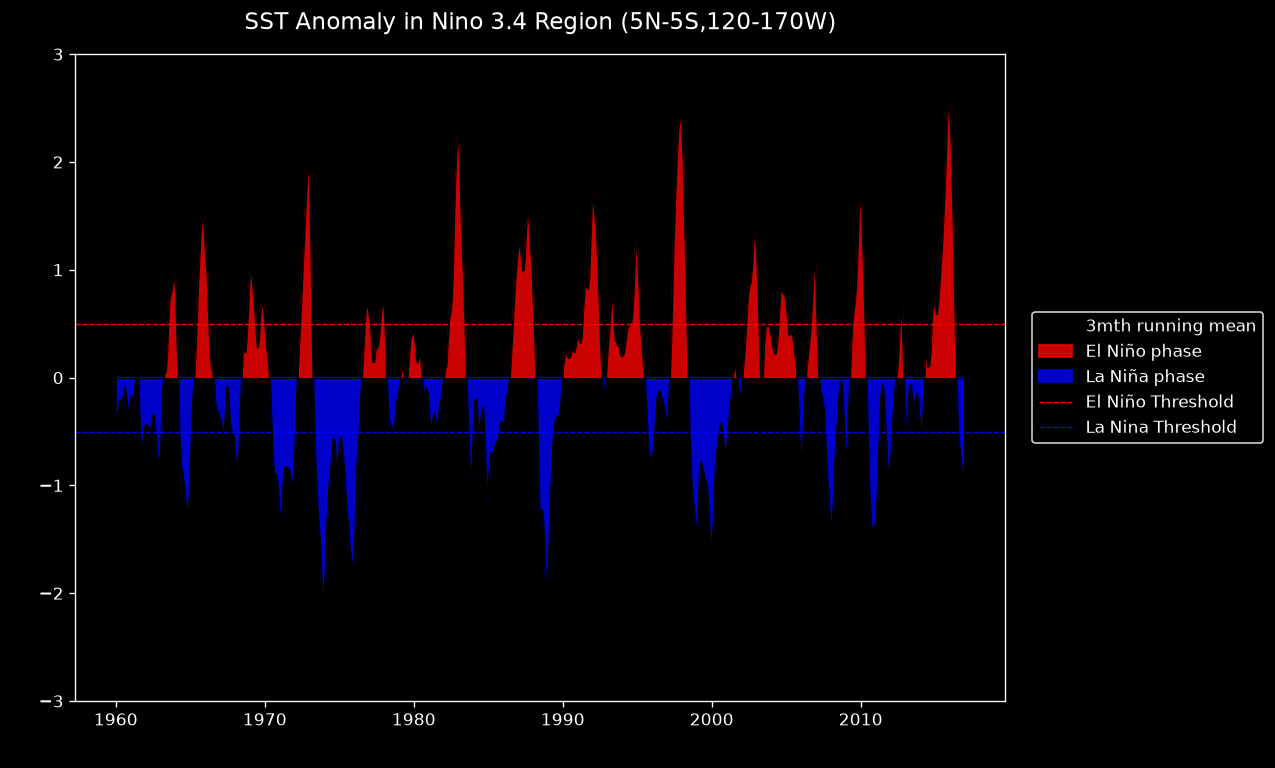

In [26]:
#2.1
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
ds.data_vars
sst = ds["sst"]

# 确定Nino3.4区域，5°N ~ 5°S，120°W ~ 170°W；lon 0~360坐标系：170W=190E，120W=240E
sst_nino34 = sst.sel(lat=slice(-5, 5), lon=slice(190, 240))

# 同一时刻，区域内所有网格求平均
sst_nino34_ts = sst_nino34.mean(dim=["lat", "lon"])

# 按月分组求多年平均气候态
sst_clim = sst_nino34_ts.groupby('time.month').mean()
sst_clim

# 计算异常值，原始序列减去同月气候态
sst_anom = sst_nino34_ts.groupby("time.month") - sst_clim

#绘图
plt.figure(figsize=(12, 4), dpi=120)
plt.plot(sst_anom.time.values, sst_anom, color='#2ca02c', linewidth=1)
plt.title('Nino3.4 SST Anomaly', fontsize=13)
plt.ylabel('SST Anomaly (°C)')
plt.xlabel('Year')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



#2.2
# 求3个月滑动平均
oni = sst_anom.rolling(time=3, center=True).mean()

fig, ax = plt.subplots(figsize=(10,7), dpi=120)
# 绘制黑色3月滑动平均曲线
ax.plot(oni.time.values, oni.values, color="black", lw=1.2, label="3mth running mean")

# ONI 大于 0 的区域填充红色（厄尔尼诺相位），小于 0 的区域填充蓝色（拉尼娜相位），同时给填充区域设置图例标签
ax.fill_between(oni.time.values, oni.values, 0, where=oni.values>0, color="red", alpha=0.8, label="El Niño phase")
ax.fill_between(oni.time.values, oni.values, 0, where=oni.values<0, color="blue", alpha=0.8, label="La Niña phase")

# 绘制阈值线，+0.5℃红色虚线、-0.5℃蓝色虚线，以及 0 距平基准黑线；阈值线添加图例标签
ax.axhline(y=0.5, color="red", linestyle="--", lw=0.8, label="El Niño Threshold")
ax.axhline(y=-0.5, color="blue", linestyle="--", lw=0.8, label="La Nina Threshold")
ax.axhline(y=0, color="black", lw=0.7)

# 设置坐标轴、标题
ax.set_title("SST Anomaly in Nino 3.4 Region (5N-5S,120-170W)", fontsize=14, pad=15)
ax.set_ylabel("Anomaly in °C", fontsize=12)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylim(-3.0, 3.0)

# 图例设置
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), framealpha=1)
plt.show()


<xarray.Dataset> Size: 4MB
Dimensions:           (time: 58662)
Coordinates:
  * time              (time) datetime64[ns] 469kB 2003-12-09T01:15:00 ... 202...
Data variables:
    time_utc          (time) |S25 1MB ...
    mf                (time) float32 235kB ...
    mf_repeatability  (time) float32 235kB ...
    mf_variability    (time) float32 235kB ...
    mf_count          (time) float64 469kB ...
    inlet_height      (time) float32 235kB ...
    sampling_period   (time) float64 469kB ...
    instrument_type   (time) float32 235kB ...
Attributes: (12/14)
    Conventions:        CF-1.8
    title:              AGAGE MHD CF4 high-frequency measurements
    site_code:          MHD
    station_long_name:  Mace Head, Ireland
    network:            AGAGE
    species:            CF4
    ...                 ...
    start_date:         2003-12-09T01:15:00+00:00
    end_date:           2025-06-30T22:39:00+00:00
    source_file:        agage_mhd_cf4_20260716.csv
    source_sha256:      0639fe6

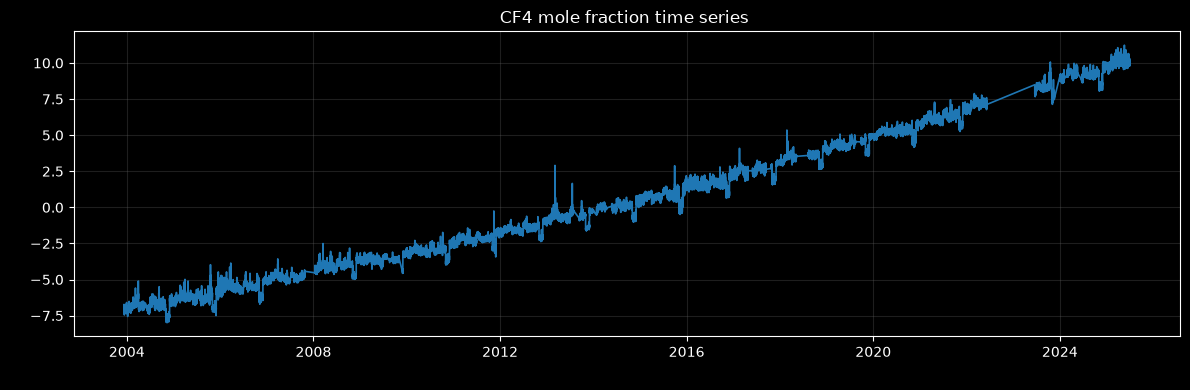

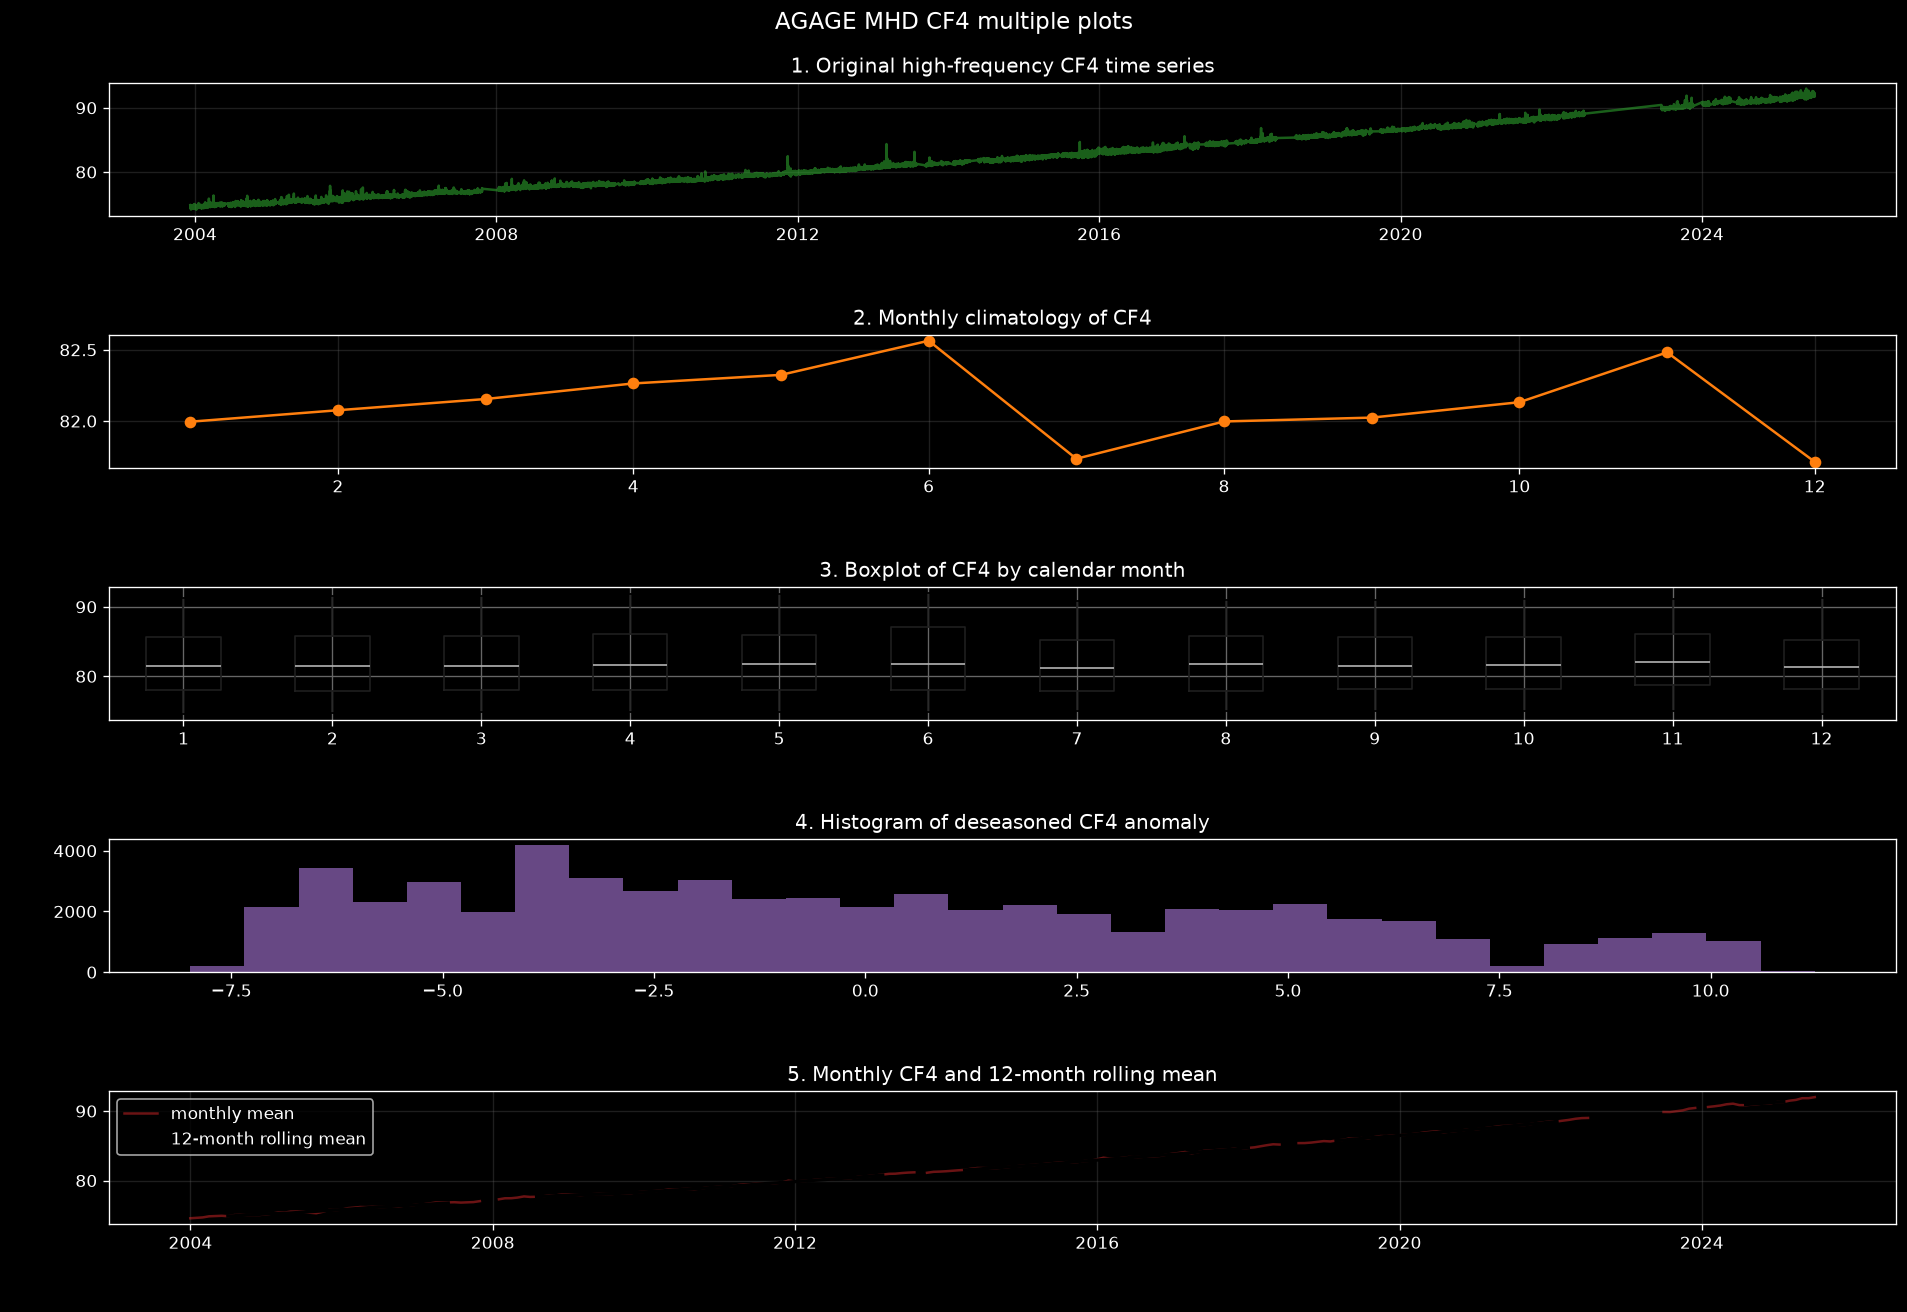

In [34]:
# 3.1
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
# 读取文件，并查看目标变量CF4浓度的列名为mf
ds = xr.open_dataset("agage_mhd_cf4_20260716.nc")
print(ds)
da = ds["mf"]
# 按月份分组，获取12个月该点多年均值。按月份分组后每个原始观测值减去它对应月份的多年平均气候值
climatology = da.groupby("time.month").mean(dim="time")
da_deseason = da.groupby("time.month") - climatology

#绘图
plt.figure(figsize=(12, 4))
da_deseason.plot(color="#1f77b4", linewidth=1.2)
plt.title(f"CF4 mole fraction time series ", fontsize=12)
plt.ylabel(f"anomaly")
plt.xlabel("Time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3.2
fig, axes = plt.subplots(5,1, figsize=(16,11), dpi=120)  

# 图1 原始高频时间序列表
da.plot(ax=axes[0], c="#2ca02c", alpha=0.6, markersize=1)
axes[0].set_title(f"1. Original high-frequency CF4 time series")
axes[0].grid(alpha=0.3)

# 图2 1–12月的月气候态
monthly_climatology.plot(ax=axes[1], marker="o", c="#ff7f0e")
axes[1].set_title(f"2. Monthly climatology of CF4")
axes[1].set_xlabel("Month")
axes[1].grid(alpha=0.3)

# 图3 按月箱线图
df_month = da_monthly.to_dataframe().reset_index()
# 新增一列month，提取月份
df_month["month"] = df_month["time"].dt.month
df_month.boxplot(column="mf", by="month", ax=axes[2])
axes[2].set_title(f"3. Boxplot of CF4 by calendar month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel(var_name)

# 图4 去季节循环异常直方图
da_deseason.plot.hist(bins=30, ax=axes[3], color="#9467bd", alpha=0.7)
axes[3].set_title(f"4. Histogram of deseasoned CF4 anomaly")
axes[3].set_xlabel(f"anomaly")

# 图5 CF₄月均值与 12 个月滑动平均
da_rolling = da_monthly.rolling(time=12, center=True).mean()
da_monthly.plot(ax=axes[4], c="#d62728", alpha=0.5, label="monthly mean")
da_rolling.plot(ax=axes[4], c="black", linewidth=2, label="12-month rolling mean")
axes[4].set_title(f"5. Monthly CF4 and 12-month rolling mean")
axes[4].legend()
axes[4].grid(alpha=0.3)

plt.suptitle(f"AGAGE MHD CF4 multiple plots", y=0.99, fontsize=14)
plt.tight_layout()
plt.show()

###### 